In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import sklearn, xgboost
import sklearn.linear_model
import numpy as np

Complete the notebook and do all the exercises. Sometimes some part of code is given as a solution, othertimes you are supposed to do it from scratch.

[Note:] You can find the solution of most of the exercises just by looking at the documentation and examples from sklearn.

# Regression

### Data generation

In [ ]:
# Read the dataset
import pandas
df = pandas.read_csv('data/athletes.csv')
df.head(), len(df)

(   Female  Age_y  Weight_kg  Height_cm  LV_mass_g  Athlete
 0     1.0   31.0       54.0      163.0       65.3      1.0
 1     1.0   39.0       54.0      162.0       91.5      1.0
 2     1.0   33.0       65.0      176.0        NaN      1.0
 3     1.0   41.0       55.0      160.0       76.9      1.0
 4     0.0   27.0       67.0      174.0        NaN      1.0,
 261)

In [ ]:
df_train, df_test = sklearn.model_selection.train_test_split(df.dropna(), test_size=0.2)


# Classification using a linear model

In [21]:
lm.intercept_

np.float64(2.2960822695334904)

Weight_kg             -0.024926142871908065
Intercept             2.2960822695334904


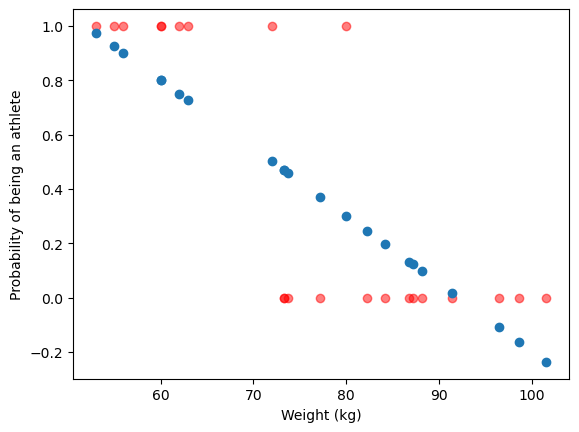

In [22]:
features = ['Weight_kg']
lm = sklearn.linear_model.LinearRegression()
lm.fit(df_train[features], df_train['Athlete'])

for i, p in enumerate(features):
    print(p, ' ' * (20 - len(p)), lm.coef_[i])
print('Intercept', ' ' * (20 - len('Intercept')), lm.intercept_ )

plt.plot(df_test['Weight_kg'], lm.predict(df_test[features]), 'o')
plt.xlabel('Weight (kg)')
plt.ylabel('Probability of being an athlete')
plt.scatter(df_test['Weight_kg'], df_test['Athlete'], color='red', alpha=0.5)

# Classification : Logistic regression

Weight_kg             -0.31634824177012894
Intercept             22.852946668480698


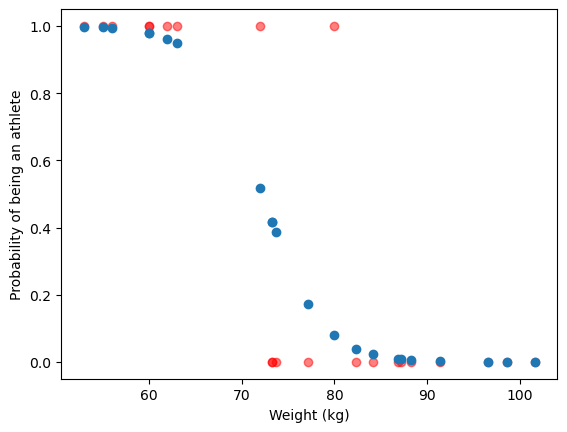

In [ ]:
features = ['Weight_kg']
logistic = sklearn.linear_model.LogisticRegression()
logistic.fit(df_train[features], df_train['Athlete'])

for i, p in enumerate(features):
    print(p, ' ' * (20 - len(p)), logistic.coef_[0][i])
print('Intercept', ' ' * (20 - len('Intercept')), logistic.intercept_[0]   )

plt.plot(df_test['Weight_kg'], logistic.predict_proba(df_test[features])[:, 1], 'o')
plt.xlabel('Weight (kg)')
plt.ylabel('Probability of being an athlete')
plt.scatter(df_test['Weight_kg'], df_test['Athlete'], color='red', alpha=0.5)

### Example: why linear regression gives bad results with labeled outcome

Check what happens if you change the features

In [ ]:
features = ['Height_cm', 'Weight_kg', 'Age_y', 'LV_mass_g', 'Female']
logistic = sklearn.linear_model.LogisticRegression()
logistic.fit(df_train[features], df_train['Athlete'])
sklearn.metrics.roc_auc_score(df_test['Athlete'], logistic.predict_proba(df_test[features])[:, 1]), sklearn.metrics.roc_auc_score(df_test['Athlete'], logistic.predict(df_test[features]))

for i, p in enumerate(features):
    print(p, ' ' * (20 - len(p)), logistic.coef_[0][i])
print('Intercept', ' ' * (20 - len('Intercept')), logistic.intercept_[0]   )

Height_cm             0.03186482227653056
Weight_kg             -0.31031885194254344
LV_mass_g             -0.008858275983008526
Female                0.4384600331844956
Intercept             17.669748370005028


In [ ]:
# Exercise. Change the Height from cm to m and check the effect on the model coefficients. Why?